# Лабораторная работа №1: регрессия (Wine Quality)

**Задача.** По химическому составу вина (спирт, кислотность, сахар и т. д.) предсказать его оценку `quality` от 3 до 9. Это *регрессия*: предсказываем число.

**Данные.** Wine Quality (UCI): красное и белое вино вместе, 6497 вин, плюс признак `is_red`.

**Метрика.** RMSE (основная) и MAE. **Порог: RMSE < 0.70.**

**Главное правило.** Тест — это «экзамен»: мы открываем его один раз, в самом конце. Всё остальное (выбор модели и настроек) делаем на train с помощью кросс-валидации.

**План:** 1) данные и разбиение, 2) EDA, 3) метрики, 4) baseline, 5) линейная регрессия и Ridge + RBF, 6) Random Forest, 7) Gradient Boosting, 8) сравнение, 9) feature importance, 10) анализ ошибок, 11) итоги.

### Основные понятия

* **Признак (feature)** — одна характеристика объекта (спирт, кислотность…). **Целевая переменная (target)** — то, что предсказываем (`quality`).
* **Модель** — алгоритм, который по признакам выдаёт предсказание. **Обучить** — подобрать её внутренние параметры по данным.
* **Train / test** — часть данных для обучения / часть «в сейфе» для финальной проверки.
* **`random_state` (seed)** — число, фиксирующее «случайность», чтобы результат повторялся при каждом запуске.
* **Baseline** — самое простое предсказание (константа), точка отсчёта: модель должна быть заметно лучше.
* **RMSE, MAE** — две меры средней ошибки (подробнее в разделе 3).
* **Кросс-валидация** — train делится на 5 частей, модель по очереди учится на четырёх и проверяется на пятой; так оцениваем модель, не трогая test.
* **Гиперпараметры** — настройки модели, которые выбираем мы сами (число деревьев, глубина…).
* **Переобучение** — модель заучила шум обучающих данных: на train отлично, на новых данных хуже.
* **Feature importance** — насколько признак помогает модели предсказывать (это не причина!).
* **Ridge** — линейная регрессия со штрафом за большие коэффициенты. **RBF-признаки** — «насколько объект похож на опорный».

In [1]:
import io, zipfile, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

SEED = 42          # один seed на весь ноутбук — эксперимент воспроизводим
np.random.seed(SEED)

## 1. Загрузка данных и разбиение на train/test

Файлы лежат в папке `data/` (если их нет, ноутбук сам скачает их с UCI).

In [2]:
DATA = Path('data'); DATA.mkdir(exist_ok=True)

def load_wine():
    red, white = DATA / 'winequality-red.csv', DATA / 'winequality-white.csv'
    if not (red.exists() and white.exists()):
        url = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
        with urllib.request.urlopen(url) as resp:
            zipfile.ZipFile(io.BytesIO(resp.read())).extractall(DATA)
    df_red = pd.read_csv(red, sep=';').assign(is_red=1)
    df_white = pd.read_csv(white, sep=';').assign(is_red=0)
    return pd.concat([df_red, df_white], ignore_index=True)

df = load_wine()
print('Размер таблицы:', df.shape, '| пропусков:', int(df.isna().sum().sum()))
df.head()

Размер таблицы: (6497, 13) | пропусков: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


### Разбиение на train и test

* **Размер: 80% / 20%** (5197 и 1300 вин). Данных немного, поэтому для обучения нужно много; 1300 вин в тесте хватает для устойчивой оценки.
* **Способ: случайное, со стратификацией по `quality`.** Стратификация значит, что доля каждой оценки одинакова в train и test. Это важно для редких оценок: «девятка» встречается 5 раз на весь датасет и без стратификации могла бы целиком попасть в одну часть.
* **`random_state=42`** фиксирует случайность: деление одинаково при каждом запуске.
* **Почему нельзя многократно смотреть на test.** Если пробовать много моделей и выбирать лучшую по тесту, мы подгоняем решение под этот тест, и результат оказывается завышенным. Поэтому всё выбираем кросс-валидацией внутри train, а test открываем один раз.

In [3]:
X = df.drop(columns='quality')
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

print(f'train: {X_train.shape[0]} объектов, test: {X_test.shape[0]} объектов')
share = pd.DataFrame({'train, %': y_train.value_counts(normalize=True).sort_index() * 100,
                      'test, %': y_test.value_counts(normalize=True).sort_index() * 100}).round(2)
share

train: 5197 объектов, test: 1300 объектов


,"train, %","test, %"
quality,,
3,0.46,0.46
4,3.33,3.31
5,32.90,32.92
6,43.66,43.62
7,16.61,16.62
8,2.96,3.00
9,0.08,0.08


Доли каждой оценки в train и test практически совпадают, то есть стратификация сработала.

### Дубликаты

В данных 18% полностью одинаковых строк. При случайном делении копия вина из теста может лежать в train, и модель просто «вспоминает» ответ, поэтому оценка получается оптимистичнее. Чтобы не обманывать себя, ниже мы отдельно считаем метрики на **«новых» тестовых винах** (чьих признаков нет в train). Для этого используются только признаки, ответы теста не нужны.

In [4]:
n_dup_all = int(df.duplicated().sum())
n_dup_train = int(pd.concat([X_train, y_train], axis=1).duplicated().sum())
print(f'Полных дубликатов во всей таблице: {n_dup_all} из {len(df)} ({n_dup_all/len(df):.1%}); в train: {n_dup_train}')

# есть ли объекты с одинаковыми признаками, но разной quality (шум разметки)?
feat_cols = list(X.columns)
conflict = df.groupby(feat_cols)['quality'].nunique()
print('Групп с одинаковыми признаками, но разной quality:', int((conflict > 1).sum()))

# "новые" объекты теста: признаков нет среди строк train (сравнение по хешу строки признаков)
h = lambda A: pd.util.hash_pandas_object(A, index=False)
seen_in_train = h(X_test).isin(set(h(X_train))).values
is_new = ~seen_in_train
print(f'Объектов теста, чьи признаки встречаются в train: {seen_in_train.sum()} из {len(X_test)}')
print(f'Объектов теста, которых в train нет ("новые"):  {is_new.sum()}')

Полных дубликатов во всей таблице: 1177 из 6497 (18.1%); в train: 791
Групп с одинаковыми признаками, но разной quality: 0
Объектов теста, чьи признаки встречаются в train: 357 из 1300
Объектов теста, которых в train нет ("новые"):  943


### Итог раздела 1: задача, данные, разбиение

Я решала задачу регрессии: предсказать оценку вина `quality` от 3 до 9 по химическому составу. Данные Wine Quality с UCI, красное и белое вино объединены, 6497 образцов, 11 признаков и признак `is_red`. Пропусков нет.

Данные разделены на train 80% и test 20% случайным разбиением со стратификацией по `quality`, `random_state=42`. Train нужен, чтобы учить модель, test — чтобы честно проверить её на данных, которых она не видела. Если проверять на тех же данных, на которых учились, качество будет завышено. Тест я использую один раз в конце: если выбирать модель по нему многократно, мы подгоним решение под этот тест, и оценка будет оптимистичной. Всё подбирается на кросс-валидации внутри train.

## 2. Разведочный анализ данных (EDA)

Чтобы анализ не повлиял на решения, касающиеся теста, **весь EDA делается только на train**. Тест при этом остаётся «закрытым».

In [5]:
train = X_train.assign(quality=y_train)
train.describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)

,mean,std,min,50%,max
fixed acidity,7.221,1.286,4.200,7.000,15.900
volatile acidity,0.340,0.166,0.080,0.290,1.580
citric acid,0.318,0.146,0.000,0.310,1.660
residual sugar,5.476,4.786,0.600,3.000,65.800
chlorides,0.056,0.034,0.009,0.047,0.611
free sulfur dioxide,30.548,17.647,1.000,29.000,289.000
total sulfur dioxide,115.964,56.738,6.000,118.000,440.000
density,0.995,0.003,0.987,0.995,1.039
pH,3.219,0.161,2.720,3.210,4.010
sulphates,0.532,0.147,0.230,0.510,1.950


**Вывод.** Признаки измерены в очень разных масштабах (плотность ≈ 0.99, диоксид серы до 440), поэтому коэффициенты линейной модели нельзя сравнивать «как есть». У `residual sugar`, `chlorides`, `free sulfur dioxide` длинные «хвосты» (максимум в десятки раз больше медианы).

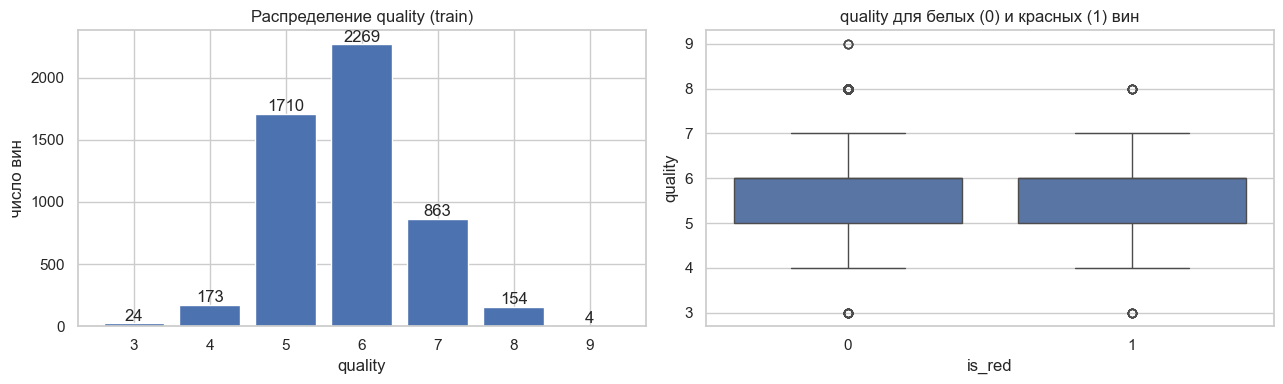

        count   mean    std
is_red                     
0        3904  5.884  0.889
1        1293  5.619  0.791

Среднее quality (train): 5.818 | std: 0.873


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = train['quality'].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color='#4C72B0')
for q, c in counts.items():
    axes[0].text(q, c + 20, str(c), ha='center')
axes[0].set(title='Распределение quality (train)', xlabel='quality', ylabel='число вин')

sns.boxplot(data=train, x='is_red', y='quality', ax=axes[1])
axes[1].set(title='quality для белых (0) и красных (1) вин', xlabel='is_red')
plt.tight_layout(); plt.show()

print(train.groupby('is_red')['quality'].agg(['count', 'mean', 'std']).round(3))
print('\nСреднее quality (train):', round(train['quality'].mean(), 3), '| std:', round(train['quality'].std(), 3))

**Выводы.**

* Оценки сконцентрированы в центре: 5 и 6 дают 76% вин, оценок 3, 4, 8, 9 мало («девятка» — 4 штуки в train). Значит, на редких оценках модель будет ошибаться чаще.
* Разброс (std) оценок ≈ 0.87: это и есть ошибка «тупого» прогноза средним. Порог 0.70 требует заметно лучше.
* Красные вина оцениваются чуть ниже (≈5.62 против ≈5.88), `is_red` оставляем.

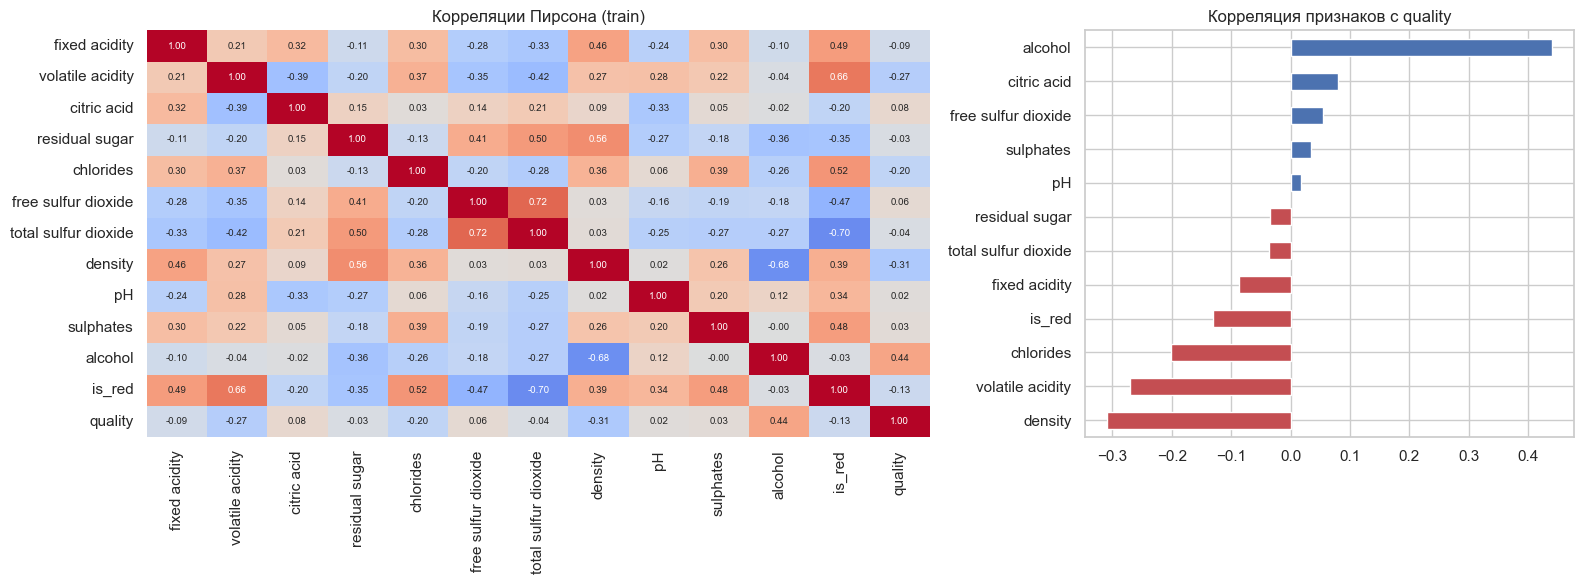

density                -0.309
volatile acidity       -0.270
chlorides              -0.201
is_red                 -0.131
fixed acidity          -0.087
total sulfur dioxide   -0.036
residual sugar         -0.035
pH                      0.017
sulphates               0.034
free sulfur dioxide     0.055
citric acid             0.080
alcohol                 0.440
Name: quality, dtype: float64

In [7]:
corr = train.corr()
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.6, 1]})
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 7}, cbar=False, ax=axes[0])
axes[0].set_title('Корреляции Пирсона (train)')
cq = corr['quality'].drop('quality').sort_values()
cq.plot.barh(ax=axes[1], color=['#C44E52' if v < 0 else '#4C72B0' for v in cq])
axes[1].set_title('Корреляция признаков с quality')
plt.tight_layout(); plt.show()
cq.round(3)

**Выводы по корреляциям.**

* **`alcohol`: r ≈ +0.44.** Самая сильная связь: чем крепче вино, тем в среднем выше оценка.
* **`density`: r ≈ −0.31**, но плотность сама зависит от спирта (`density` и `alcohol`: −0.68), то есть частично дублирует его.
* `volatile acidity` (−0.27) и `chlorides` (−0.20): больше «уксусной» кислотности и соли значит хуже оценка.
* У `pH`, `sulphates`, `free sulfur dioxide`, `residual sugar` линейная корреляция почти нулевая (|r| < 0.06), но выбрасывать их нельзя: корреляция не видит нелинейных связей.
* Признаки частично дублируют друг друга (например, free и total SO₂: 0.72).
* **Корреляция не означает причину.** У хороших вин больше спирта, но если долить спирт в обычное вино, оценка не вырастет: и то и другое следствие зрелости винограда.

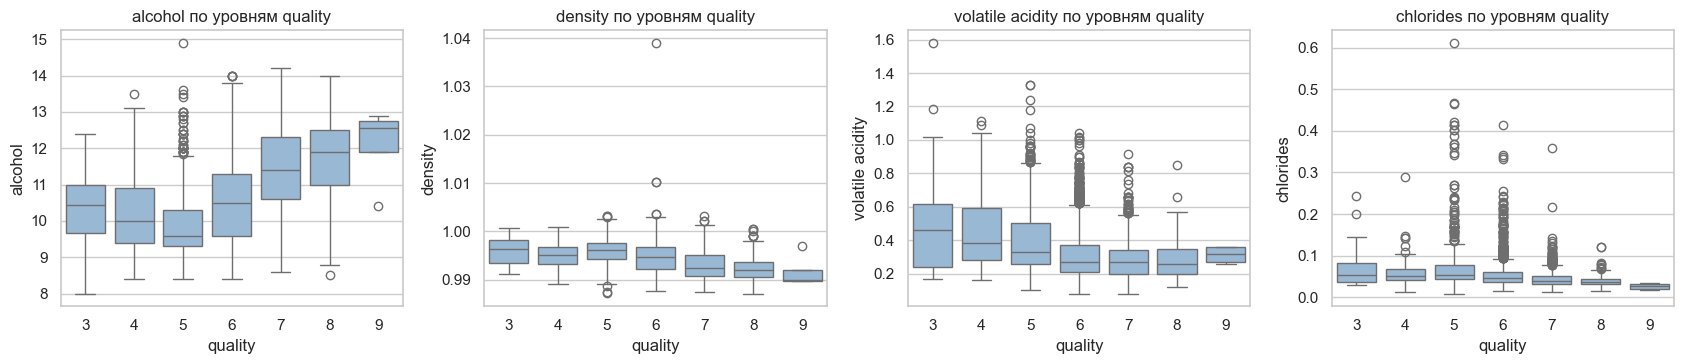

Доля выбросов по правилу 1.5*IQR, %:
citric acid             6.4
fixed acidity           5.4
volatile acidity        5.0
chlorides               4.3
sulphates               2.9
residual sugar          1.8
pH                      1.1
free sulfur dioxide     0.8
total sulfur dioxide    0.2
density                 0.1
alcohol                 0.1


In [8]:
top = ['alcohol', 'density', 'volatile acidity', 'chlorides']
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col in zip(axes, top):
    sns.boxplot(data=train, x='quality', y=col, ax=ax, color='#8FB8DE')
    ax.set_title(f'{col} по уровням quality')
plt.tight_layout(); plt.show()

# выбросы по правилу 1.5*IQR
q1, q3 = X_train.quantile(.25), X_train.quantile(.75); iqr = q3 - q1
out_share = (((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).mean() * 100).round(1)
print('Доля выбросов по правилу 1.5*IQR, %:'); print(out_share.drop('is_red').sort_values(ascending=False).to_string())

**Выводы.** От оценки 5 к 8 спирт растёт, а `volatile acidity` и `chlorides` падают. Выбросов много (4–6% в нескольких признаках), но мы их **не удаляем**: это реальные вина, а деревья к выбросам устойчивы. Пропусков нет, кодировать категории не нужно.

### Итог раздела 2: анализ данных

Оценки сконцентрированы в центре: 5 и 6 дают 76% вин, редких оценок 3, 4, 8, 9 мало. Самый сильный признак — алкоголь, корреляция 0.44 с качеством: чем крепче вино, тем в среднем выше оценка. Следом летучая кислотность (минус 0.27) и плотность (минус 0.31), но плотность зависит от спирта, поэтому дублирует его. Корреляция не означает причинность.

## 3. Метрики

Ошибка = настоящая оценка − предсказание.

* **MAE** — средний модуль ошибки: «в среднем ошибаемся на столько баллов».
* **RMSE** — ошибки возводятся в квадрат, усредняются, затем берётся корень. Из-за квадрата **большие ошибки штрафуются сильнее**: одна ошибка 3 даёт вклад 9, три ошибки по 1 — всего 3.
* **Почему на одной модели они различаются.** RMSE всегда не меньше MAE. Чем неравномернее ошибки (много мелких и несколько огромных), тем больше разрыв.

In [9]:
# маленький пример: средняя абсолютная ошибка одинакова, а RMSE разная
equal = np.array([1, 1, 1, 1]); spiky = np.array([0, 0, 0, 4])
for name, e in [('ровные ошибки [1,1,1,1]', equal), ('одна крупная [0,0,0,4]', spiky)]:
    print(f'{name}: MAE = {np.abs(e).mean():.2f}, RMSE = {np.sqrt((e**2).mean()):.2f}')

ровные ошибки [1,1,1,1]: MAE = 1.00, RMSE = 1.00
одна крупная [0,0,0,4]: MAE = 1.00, RMSE = 2.00


### Как сравниваем честно

* Все модели учатся на одном train и проверяются на одном test.
* Настройки и выбор лучшей модели — только по **5-fold кросс-валидации на train** (test не трогаем).
* Масштабирование спрятано внутрь `Pipeline`, чтобы в каждом фолде оно училось только на обучающей части.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def rmse(y_true, y_pred): return float(np.sqrt(mean_squared_error(y_true, y_pred)))
def mae(y_true, y_pred):  return float(mean_absolute_error(y_true, y_pred))

def cv_rmse(model):
    """RMSE на 5 фолдах train: возвращает (среднее, std по фолдам)."""
    s = -cross_val_score(model, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    return s.mean(), s.std()

results = {}   # здесь соберём итоговые числа каждой модели

def evaluate_model(name, model, cv_scores):
    """Финальная оценка: train / test / "новые" объекты теста."""
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    results[name] = {
        'CV RMSE': cv_scores[0], 'CV std': cv_scores[1],
        'Train RMSE': rmse(y_train, p_tr),
        'Test RMSE': rmse(y_test, p_te), 'Test MAE': mae(y_test, p_te),
        'New RMSE': rmse(y_test[is_new], p_te[is_new]), 'New MAE': mae(y_test[is_new], p_te[is_new]),
    }
    return p_te

## 4. Baseline

**Baseline** — самое простое предсказание, с которым сравниваем всё остальное: всем винам одна и та же константа. Если модель не лучше baseline, она ничего не извлекла из признаков.

**Какую константу брать.** Для RMSE оптимально **среднее** (для MAE — медиана). Считаем только по train: ответы теста использовать нельзя.

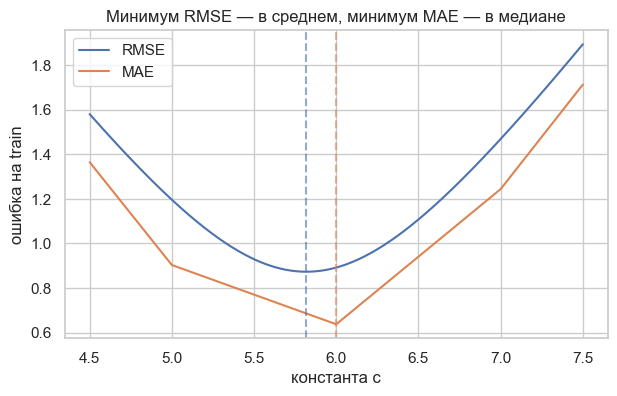

среднее train = 5.818, медиана train = 6.0


In [11]:
c_grid = np.linspace(4.5, 7.5, 301)
curve = pd.DataFrame({'c': c_grid,
                      'RMSE': [rmse(y_train, np.full(len(y_train), c)) for c in c_grid],
                      'MAE':  [mae(y_train,  np.full(len(y_train), c)) for c in c_grid]})
mean_c, median_c = y_train.mean(), y_train.median()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve.c, curve.RMSE, label='RMSE'); ax.plot(curve.c, curve.MAE, label='MAE')
ax.axvline(mean_c, color='C0', ls='--', alpha=.6); ax.axvline(median_c, color='C1', ls='--', alpha=.6)
ax.set(xlabel='константа c', ylabel='ошибка на train', title='Минимум RMSE — в среднем, минимум MAE — в медиане')
ax.legend(); plt.show()
print(f'среднее train = {mean_c:.3f}, медиана train = {median_c:.1f}')

In [12]:
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)    # константа = среднее по train
evaluate_model('Baseline', baseline, cv_rmse(baseline))
pd.DataFrame(results).T.round(4)[['CV RMSE', 'Test RMSE', 'Test MAE']]

,CV RMSE,Test RMSE,Test MAE
Baseline,0.8732,0.8738,0.6861


RMSE baseline ≈ 0.87: почти равно разбросу самих оценок, константа ничего не объясняет. Любая модель должна быть заметно лучше и, чтобы пройти порог, опуститься ниже 0.70.

### Итог разделов 3–4: метрики и baseline

Основная метрика RMSE, дополнительная MAE. MAE — средний модуль ошибки, RMSE возводит ошибки в квадрат, поэтому сильнее штрафует крупные промахи, и всегда не меньше MAE. Baseline — предсказание одной константой, средним по train, потому что для RMSE среднее оптимально. Он нужен как нулевая точка отсчёта: если модель не лучше него, она ничего не извлекла из признаков. RMSE baseline 0.874.

## 5. Линейная регрессия

Модель: `оценка = b0 + b1·признак1 + b2·признак2 + …`, то есть взвешенная сумма признаков.

**Нужно ли масштабирование?** Для предсказаний нет (ниже проверим: они не меняются). Для **сравнения коэффициентов да**: у признаков разные единицы, а коэффициент означает «изменение оценки при росте признака на единицу». После стандартизации (вычесть среднее, поделить на std) коэффициенты сравнимы.

In [13]:
lr = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]).fit(X_train, y_train)
lr_raw = LinearRegression().fit(X_train, y_train)      # без масштабирования — только для проверки

print('Предсказания с масштабированием и без него совпадают:',
      np.allclose(lr.predict(X_test), lr_raw.predict(X_test)))

evaluate_model('Linear Regression', lr, cv_rmse(lr))
pd.DataFrame(results).T.round(4)[['CV RMSE', 'Train RMSE', 'Test RMSE', 'Test MAE']]

Предсказания с масштабированием и без него совпадают: True


,CV RMSE,Train RMSE,Test RMSE,Test MAE
Baseline,0.8732,0.8730,0.8738,0.6861
Linear Regression,0.7377,0.7337,0.7280,0.5678


                      coef (исходный масштаб)  coef (стандартизованный)  |std coef|
density                              -107.254                    -0.323       0.323
residual sugar                          0.065                     0.309       0.309
alcohol                                 0.215                     0.256       0.256
volatile acidity                       -1.462                    -0.242       0.242
is_red                                  0.309                     0.134       0.134
fixed acidity                           0.087                     0.112       0.112
sulphates                               0.745                     0.109       0.109
total sulfur dioxide                   -0.002                    -0.091       0.091
pH                                      0.548                     0.088       0.088
free sulfur dioxide                     0.005                     0.086       0.086
chlorides                              -0.635                    -0.022     

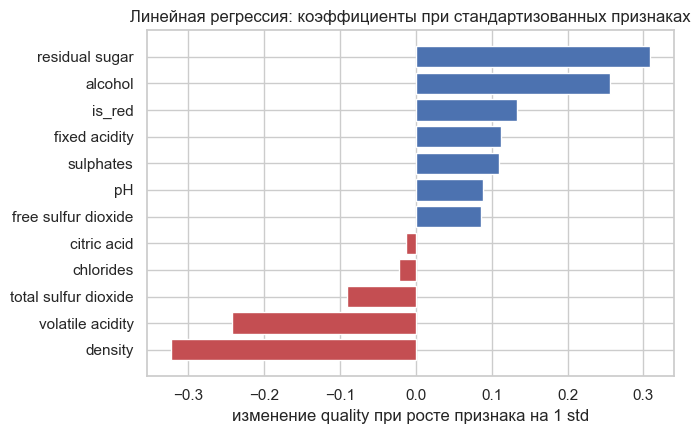

In [14]:
coef = pd.DataFrame({
    'coef (исходный масштаб)': lr_raw.coef_,
    'coef (стандартизованный)': lr.named_steps['model'].coef_,
}, index=X.columns)
coef['|std coef|'] = coef['coef (стандартизованный)'].abs()
coef = coef.sort_values('|std coef|', ascending=False)
print(coef.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
s = coef['coef (стандартизованный)'].sort_values()
ax.barh(s.index, s.values, color=['#C44E52' if v < 0 else '#4C72B0' for v in s])
ax.set(title='Линейная регрессия: коэффициенты при стандартизованных признаках',
       xlabel='изменение quality при росте признака на 1 std')
plt.tight_layout(); plt.show()

In [15]:
# VIF: насколько признак линейно предсказывается остальными (VIF > 10 — сильная мультиколлинеарность)
def vif(frame):
    out = {}
    for col in frame.columns:
        r2 = LinearRegression().fit(frame.drop(columns=col), frame[col]).score(frame.drop(columns=col), frame[col])
        out[col] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)
vif(X_train).round(1)

density                 21.7
residual sugar           9.7
is_red                   7.1
alcohol                  5.4
fixed acidity            5.0
total sulfur dioxide     4.0
pH                       2.6
free sulfur dioxide      2.2
volatile acidity         2.2
chlorides                1.6
citric acid              1.6
sulphates                1.5
dtype: float64

**Выводы.**

* Масштабирование не изменило предсказания; оно нужно только для интерпретации.
* RMSE ≈ 0.73: лучше baseline, но **порог 0.70 не пройден** (улучшим в 5.1). Линейная модель видит только прямые зависимости.
* В исходном масштабе у `density` коэффициент ≈ −107 просто потому, что плотность меняется в сотых долях. Сравнивать такие числа нельзя.
* На стандартизованных признаках влияние у `density`, `residual sugar`, `alcohol`, `volatile acidity`. Но у `density` и `residual sugar` высокий VIF (признаки дублируют другие), поэтому их коэффициенты нестабильны: например, `residual sugar` почти не связан с quality, а коэффициент заметный.

### 5.1. Улучшаем линейную модель: Ridge + RBF

Обычная линейная модель не проходит порог. Оставим её линейной, но **изменим признаки**.

* **RBF-признаки.** Берём 1500 «опорных» вин из train. Новый признак = *насколько данное вино похоже на опорное* (1 — совпало, около 0 — далеко). Линейная модель поверх таких признаков умеет строить кривые зависимости, то есть по исходным признакам она теперь нелинейна. Параметр `gamma` — «ширина» понятия «похоже»: большая означает, что похожими считаются только почти одинаковые вина (модель склонна запоминать).
* **Ridge** — линейная регрессия со **штрафом за большие коэффициенты** (L2-регуляризация, `alpha` — сила штрафа). Нужен, потому что признаков 1500, и без штрафа модель подогналась бы под шум (переобучение).
* **Подбор `gamma` и `alpha`** — только по кросс-валидации на train, причём **`GroupKFold`**: копии одного вина всегда попадают в один фолд. Иначе из-за дубликатов выигрывала бы модель, которая просто запоминает.

In [16]:
# группа = одно и то же вино (одинаковые признаки); копии всегда попадают в один фолд
groups = pd.factorize(h(X_train))[0]
group_cv = GroupKFold(n_splits=5)

rbf_pipe = Pipeline([
    ('scaler', StandardScaler()),                                                # RBF чувствителен к масштабу, стандартизуем
    ('rbf', Nystroem(kernel='rbf', n_components=1500, random_state=SEED)),       # 1500 признаков "похожесть на опорное вино"
    ('ridge', Ridge()),                                                          # линейная модель с L2-штрафом
])
rbf_search = GridSearchCV(
    rbf_pipe,
    param_grid={'rbf__gamma': [0.02, 0.05, 0.1, 0.2], 'ridge__alpha': [0.3, 1, 3]},
    cv=group_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
rbf_search.fit(X_train, y_train, groups=groups)

grid_res = pd.DataFrame(rbf_search.cv_results_)
grid_res['CV RMSE'] = -grid_res['mean_test_score']
print('Лучшие параметры:', rbf_search.best_params_)
grid_res.pivot(index='param_rbf__gamma', columns='param_ridge__alpha', values='CV RMSE').round(4)

Лучшие параметры: {'rbf__gamma': 0.1, 'ridge__alpha': 1}


param_ridge__alpha,0.3,1.0,3.0
param_rbf__gamma,,,
0.02,0.6954,0.7002,0.7076
0.05,0.6908,0.6915,0.6961
0.10,0.6933,0.6894,0.6923
0.20,0.7049,0.6950,0.6962


In [17]:
rbf_ridge = rbf_search.best_estimator_            # уже обучена на всём train
rbf_cv = cv_rmse(rbf_ridge)                       # тот же обычный 5-fold, что и у остальных моделей (для сопоставимости колонки CV RMSE)
evaluate_model('Ridge + RBF', rbf_ridge, rbf_cv)
print(f'RMSE на строгой (групповой) кросс-валидации, по которой подбирали: {-rbf_search.best_score_:.4f}')
pd.DataFrame(results).T.round(4)[['CV RMSE', 'Train RMSE', 'Test RMSE', 'Test MAE', 'New RMSE']]

RMSE на строгой (групповой) кросс-валидации, по которой подбирали: 0.6894


,CV RMSE,Train RMSE,Test RMSE,Test MAE,New RMSE
Baseline,0.8732,0.8730,0.8738,0.6861,0.8891
Linear Regression,0.7377,0.7337,0.7280,0.5678,0.7344
Ridge + RBF,0.6801,0.6319,0.6686,0.5189,0.6889


**Итог.** Ridge + RBF проходит порог 0.70: на тесте ≈ 0.67, на «новых» винах ≈ 0.69, на строгой групповой кросс-валидации ≈ 0.69; на пяти других разбиениях ≈ 0.67–0.68. Запас небольшой, но стабильный. Модель лучше обычной линейной (0.73), но слабее леса и бустинга (≈ 0.59). Минус: у неё нет коэффициента на каждый исходный признак, поэтому feature importance для неё не считаем.

## 6. Random Forest

**Идея.** Решающее дерево — цепочка вопросов вроде «спирт больше 11? кислотность меньше 0.3?». Одно дерево зазубривает данные. Лес — **сотни деревьев**: каждое учится на случайной части данных и признаков, а ответ — среднее по всем. Ошибки отдельных деревьев гасятся, разброс уменьшается. Масштабирование не нужно.

Настройки (`max_features`, `min_samples_leaf`, `max_depth`) подбираем кросс-валидацией на train (`RandomizedSearchCV`, 20 вариантов).

In [18]:
rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    param_distributions={'max_features': [0.2, 0.33, 0.5, 0.7, 1.0],
                         'min_samples_leaf': [1, 2, 3, 5],
                         'max_depth': [None, 15, 25]},
    n_iter=20, cv=cv, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=1)
rf_search.fit(X_train, y_train)

res = pd.DataFrame(rf_search.cv_results_)
res['CV RMSE'] = -res['mean_test_score']
print('Лучшие параметры:', rf_search.best_params_)
res.sort_values('CV RMSE')[['param_max_features', 'param_min_samples_leaf', 'param_max_depth', 'CV RMSE']].head(6).round(4)

Лучшие параметры: {'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': None}


,param_max_features,param_min_samples_leaf,param_max_depth,CV RMSE
19,0.33,1,None,0.6130
0,0.20,1,None,0.6149
18,0.20,1,25,0.6152
16,0.50,1,None,0.6162
7,0.50,1,25,0.6167
8,0.70,1,None,0.6176


In [19]:
rf = RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1, **rf_search.best_params_)
rf_cv = cv_rmse(rf)
rf.fit(X_train, y_train)
evaluate_model('Random Forest', rf, rf_cv)
pd.DataFrame(results).T.round(4)[['CV RMSE', 'Train RMSE', 'Test RMSE', 'Test MAE']]

,CV RMSE,Train RMSE,Test RMSE,Test MAE
Baseline,0.8732,0.8730,0.8738,0.6861
Linear Regression,0.7377,0.7337,0.7280,0.5678
Ridge + RBF,0.6801,0.6319,0.6686,0.5189
Random Forest,0.6125,0.2196,0.5929,0.4238


## 7. Gradient Boosting

**Идея.** Тоже деревья, но небольшие и **строятся по очереди**: каждое новое исправляет ошибки уже построенных. Лес борется с разбросом, бустинг — с систематической ошибкой. Он обычно точнее, но чувствительнее к настройкам (число деревьев, `learning_rate`, глубина и др.), которые мы подбираем кросс-валидацией.

In [20]:
gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=SEED),
    param_distributions={'n_estimators': [300, 600, 1000],
                         'learning_rate': [0.02, 0.05, 0.1],
                         'max_depth': [3, 5, 7, 9],
                         'subsample': [0.6, 0.8, 1.0],
                         'min_samples_leaf': [1, 3, 5],
                         'max_features': [0.5, 0.8, 1.0]},
    n_iter=20, cv=cv, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=-1)
gb_search.fit(X_train, y_train)

res = pd.DataFrame(gb_search.cv_results_)
res['CV RMSE'] = -res['mean_test_score']
print('Лучшие параметры:', gb_search.best_params_)
cols = [c for c in res.columns if c.startswith('param_')] + ['CV RMSE']
res.sort_values('CV RMSE')[cols].head(6).round(4)

Лучшие параметры: {'subsample': 0.8, 'n_estimators': 1000, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 9, 'learning_rate': 0.02}


,param_subsample,param_n_estimators,param_min_samples_leaf,param_max_features,param_max_depth,param_learning_rate,CV RMSE
6,0.8,1000,1,0.8,9,0.02,0.6144
7,0.8,300,3,0.8,9,0.02,0.6225
5,0.8,600,5,0.8,7,0.05,0.6231
19,0.8,300,3,1.0,9,0.02,0.6240
4,1.0,600,5,1.0,9,0.05,0.6300
8,0.8,600,5,1.0,9,0.10,0.6307


In [21]:
gb = GradientBoostingRegressor(random_state=SEED, **gb_search.best_params_)
gb_cv = cv_rmse(gb)       # те же 5 фолдов
gb.fit(X_train, y_train)
evaluate_model('Gradient Boosting', gb, gb_cv)
pd.DataFrame(results).T.round(4)[['CV RMSE', 'Train RMSE', 'Test RMSE', 'Test MAE']]

,CV RMSE,Train RMSE,Test RMSE,Test MAE
Baseline,0.8732,0.8730,0.8738,0.6861
Linear Regression,0.7377,0.7337,0.7280,0.5678
Ridge + RBF,0.6801,0.6319,0.6686,0.5189
Random Forest,0.6125,0.2196,0.5929,0.4238
Gradient Boosting,0.6144,0.0472,0.5878,0.3910


## 8. Честное сравнение моделей

Один train, один test, одна схема кросс-валидации для всех моделей. Итоговая таблица (RMSE и MAE на тесте):

In [22]:
final = pd.DataFrame(results).T
order = ['Baseline', 'Linear Regression', 'Ridge + RBF', 'Random Forest', 'Gradient Boosting']
final = final.loc[order]
main_table = final[['Test RMSE', 'Test MAE']].rename(columns={'Test RMSE': 'RMSE', 'Test MAE': 'MAE'}).round(3)
main_table.index.name = 'Модель'
main_table

,RMSE,MAE
Модель,,
Baseline,0.874,0.686
Linear Regression,0.728,0.568
Ridge + RBF,0.669,0.519
Random Forest,0.593,0.424
Gradient Boosting,0.588,0.391


In [23]:
beat = final['Test RMSE'] < final.loc['Baseline', 'Test RMSE']
print('Превзошли baseline по RMSE:', ', '.join(final.index[beat].drop('Baseline', errors='ignore')))
print('Прошли порог RMSE < 0.70:  ', ', '.join(final.index[final['Test RMSE'] < 0.70]))

ext = final[['CV RMSE', 'Train RMSE', 'Test RMSE', 'Test MAE', 'New RMSE', 'New MAE']].copy()
ext['Test RMSE / Baseline'] = ext['Test RMSE'] / ext.loc['Baseline', 'Test RMSE']
ext.round(3)

Превзошли baseline по RMSE: Linear Regression, Ridge + RBF, Random Forest, Gradient Boosting
Прошли порог RMSE < 0.70:   Ridge + RBF, Random Forest, Gradient Boosting


,CV RMSE,Train RMSE,Test RMSE,Test MAE,New RMSE,New MAE,Test RMSE / Baseline
Baseline,0.873,0.873,0.874,0.686,0.889,0.695,1.000
Linear Regression,0.738,0.734,0.728,0.568,0.734,0.570,0.833
Ridge + RBF,0.680,0.632,0.669,0.519,0.689,0.534,0.765
Random Forest,0.612,0.220,0.593,0.424,0.683,0.523,0.679
Gradient Boosting,0.614,0.047,0.588,0.391,0.689,0.525,0.673


Колонки расширенной таблицы: **CV RMSE** — по кросс-валидации train (по ней выбираем модель); **Train RMSE** — ошибка на обучающих данных (показывает переобучение); **Test** — финальная оценка; **New** — то же, но только на тестовых винах, которых нет в train.

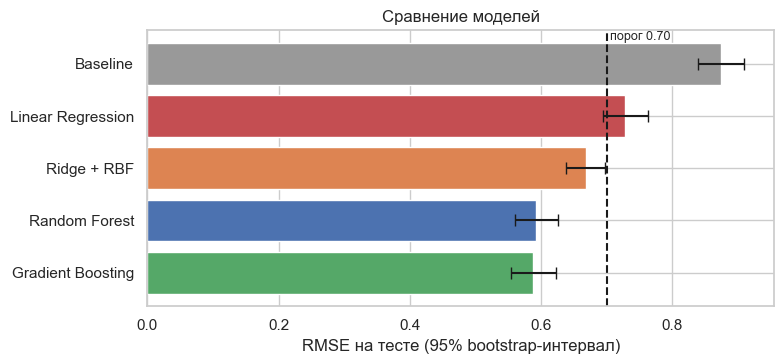

,2.5%,97.5%
Baseline,0.840,0.910
Linear Regression,0.694,0.763
Ridge + RBF,0.638,0.698
Random Forest,0.561,0.627
Gradient Boosting,0.554,0.623


In [24]:
# 95% доверительные интервалы RMSE на тесте (bootstrap по объектам теста, модели обучены, ничего не подбирается)
rng = np.random.default_rng(SEED)
preds = {'Baseline': baseline.predict(X_test), 'Linear Regression': lr.predict(X_test),
         'Ridge + RBF': rbf_ridge.predict(X_test), 'Random Forest': rf.predict(X_test), 'Gradient Boosting': gb.predict(X_test)}
idx = rng.integers(0, len(y_test), size=(1000, len(y_test)))
yt = y_test.to_numpy()
ci = {}
for name, p in preds.items():
    b = np.sqrt(((yt[idx] - p[idx]) ** 2).mean(axis=1))
    ci[name] = (np.percentile(b, 2.5), np.percentile(b, 97.5))

fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(preds)
vals = [final.loc[n, 'Test RMSE'] for n in names]
errs = [[v - ci[n][0] for n, v in zip(names, vals)], [ci[n][1] - v for n, v in zip(names, vals)]]
ax.barh(names, vals, xerr=errs, color=['#999', '#C44E52', '#DD8452', '#4C72B0', '#55A868'], capsize=4)
ax.axvline(0.70, color='k', ls='--'); ax.text(0.705, -0.45, 'порог 0.70', fontsize=9)
ax.set(xlabel='RMSE на тесте (95% bootstrap-интервал)', title='Сравнение моделей'); ax.invert_yaxis()
plt.tight_layout(); plt.show()
pd.DataFrame(ci, index=['2.5%', '97.5%']).T.round(3)

### Устойчивость к разбиению

Повторяем эксперимент на 5 других разбиениях с уже выбранными настройками, чтобы проверить, что результат не случайность `random_state=42`. Это оценка разброса, а не выбор модели.

In [25]:
rows = []
for seed in [0, 1, 2, 3, 4]:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    row = {'seed': seed, 'Baseline': rmse(yb, np.full(len(yb), ya.mean()))}
    for name, mdl in [('Linear Regression', lr), ('Ridge + RBF', rbf_ridge), ('Random Forest', rf), ('Gradient Boosting', gb)]:
        row[name] = rmse(yb, clone(mdl).fit(Xa, ya).predict(Xb))
    rows.append(row)
stab = pd.DataFrame(rows).set_index('seed')
pd.concat([stab.round(3), stab.agg(['mean', 'std']).round(3)])

,Baseline,Linear Regression,Ridge + RBF,Random Forest,Gradient Boosting
0,0.874,0.751,0.682,0.617,0.614
1,0.874,0.722,0.667,0.586,0.580
2,0.874,0.752,0.676,0.584,0.579
3,0.874,0.743,0.680,0.600,0.595
4,0.874,0.734,0.669,0.592,0.587
mean,0.874,0.740,0.675,0.596,0.591
std,0.000,0.012,0.007,0.013,0.014


### Выводы по сравнению моделей

* **Все модели лучше baseline** (0.87): признаки несут информацию о качестве.
* **Порог 0.70 проходят Ridge + RBF (≈0.67), Random Forest и Gradient Boosting (≈0.59).** Обычная линейная регрессия (0.73) нет.
* **Результат стабилен:** на пяти других разбиениях лес и бустинг 0.58–0.62, Ridge + RBF 0.67–0.68, линейная 0.72–0.75.
* **Почему деревья лучше линейных моделей.** Зависимость нелинейная, признаки влияют друг на друга (например, спирт и кислотность по-разному для красных и белых), есть выбросы. Деревья делят данные на области и в каждой считают своё.
* **Лес и бустинг почти равны** (0.593 и 0.588): разница меньше шума, интервалы перекрываются. Лес выбран **по кросс-валидации** (0.6125 против 0.6144), а не по тесту; менять выбор после просмотра теста нельзя.
* **Переобучение.** На train у леса 0.22, у бустинга 0.05, на тесте ≈ 0.59: модель почти заучила обучающие данные. Это переобучение: на train отлично, на новых данных хуже. Борьба с ним: кросс-валидация и ограничение сложности.
* **Дубликаты.** На «новых» винах ошибка деревьев выше (≈ 0.68–0.69), но порог всё равно выполняется.
* **Выбор лучшей модели** делаем по CV на train, а не по тесту (раздел 10).

### Итог разделов 5–8: модели и сравнение

Я сравнила четыре модели на одном и том же тесте, гиперпараметры подбирала кросс-валидацией на train.

**Линейная регрессия** — взвешенная сумма признаков, умеет только линейные зависимости. RMSE 0.728, порог 0.70 не проходит.

Чтобы улучшить линейную модель, я использовала **Ridge с RBF-признаками**. Ridge — это та же линейная регрессия, но со штрафом за слишком большие коэффициенты. Он нужен, чтобы модель не подгонялась под шум и не переобучалась, а признаков стало 1500. RBF-признаки — это новые признаки вида «насколько данное вино похоже на опорное вино из train». Линейная модель поверх них становится нелинейной по исходным признакам и умеет строить кривые зависимости. RMSE 0.669, порог проходит.

**Random Forest** — усреднение сотен глубоких деревьев; каждое обучено на случайной подвыборке с случайным набором признаков, ошибки отдельных деревьев гасятся, то есть уменьшается разброс. RMSE 0.593.

**Gradient Boosting** — деревья строятся последовательно, каждое исправляет ошибки предыдущих. RMSE 0.588.

Лес и бустинг лучше линейных моделей, потому что зависимость нелинейная и есть взаимодействия признаков. Между собой они различаются в пределах шума, поэтому по кросс-валидации я выбрала лес.

**Переобучение:** у леса RMSE на train 0.22, на тесте 0.59, модель частично запомнила обучающие данные. Это переобучение — когда модель подстраивается под шум train и хуже работает на новых данных. Контролирую кросс-валидацией и ограничениями сложности; в Ridge для этого используется штраф за большие коэффициенты.

## 9. Feature importance

**Важность признака** — насколько он помогает модели предсказывать. Считаем тремя способами:

1. **Встроенная важность деревьев.** Быстро, но смещена в пользу непрерывных признаков.
2. **Permutation importance** на валидационных фолдах. Мы **перемешиваем значения одного признака между строками** (его связь с оценкой разрушается) и смотрим, насколько вырос RMSE. Сильно вырос значит, что признак важен.
3. **Для линейной регрессии** — модуль стандартизованного коэффициента.

In [26]:
def cv_permutation_importance(model, n_repeats=5):
    """Рост RMSE при перемешивании признака; считается на валидационных фолдах train."""
    imps = []
    for tr_idx, va_idx in cv.split(X_train):
        m = clone(model).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        r = permutation_importance(m, X_train.iloc[va_idx], y_train.iloc[va_idx],
                                   scoring='neg_root_mean_squared_error',
                                   n_repeats=n_repeats, random_state=SEED, n_jobs=-1)
        imps.append(r.importances_mean)
    return pd.Series(np.mean(imps, axis=0), index=X_train.columns)

imp = pd.DataFrame({
    'RF impurity': pd.Series(rf.feature_importances_, index=X.columns),
    'GB impurity': pd.Series(gb.feature_importances_, index=X.columns),
    'RF permutation': cv_permutation_importance(rf),
    'GB permutation': cv_permutation_importance(gb),
    'LR |std coef|': coef['|std coef|'],
    '|corr| with quality': corr['quality'].drop('quality').abs(),
})
imp.sort_values('RF impurity', ascending=False).round(3)

,RF impurity,GB impurity,RF permutation,GB permutation,LR |std coef|,|corr| with quality
alcohol,0.176,0.207,0.165,0.172,0.256,0.440
volatile acidity,0.111,0.121,0.086,0.098,0.242,0.270
density,0.109,0.084,0.047,0.037,0.323,0.309
free sulfur dioxide,0.085,0.090,0.055,0.068,0.086,0.055
chlorides,0.082,0.068,0.034,0.023,0.022,0.201
total sulfur dioxide,0.079,0.082,0.034,0.042,0.091,0.036
residual sugar,0.075,0.081,0.030,0.040,0.309,0.035
sulphates,0.074,0.076,0.036,0.040,0.109,0.034
citric acid,0.072,0.063,0.031,0.018,0.014,0.080
pH,0.069,0.069,0.025,0.029,0.088,0.017


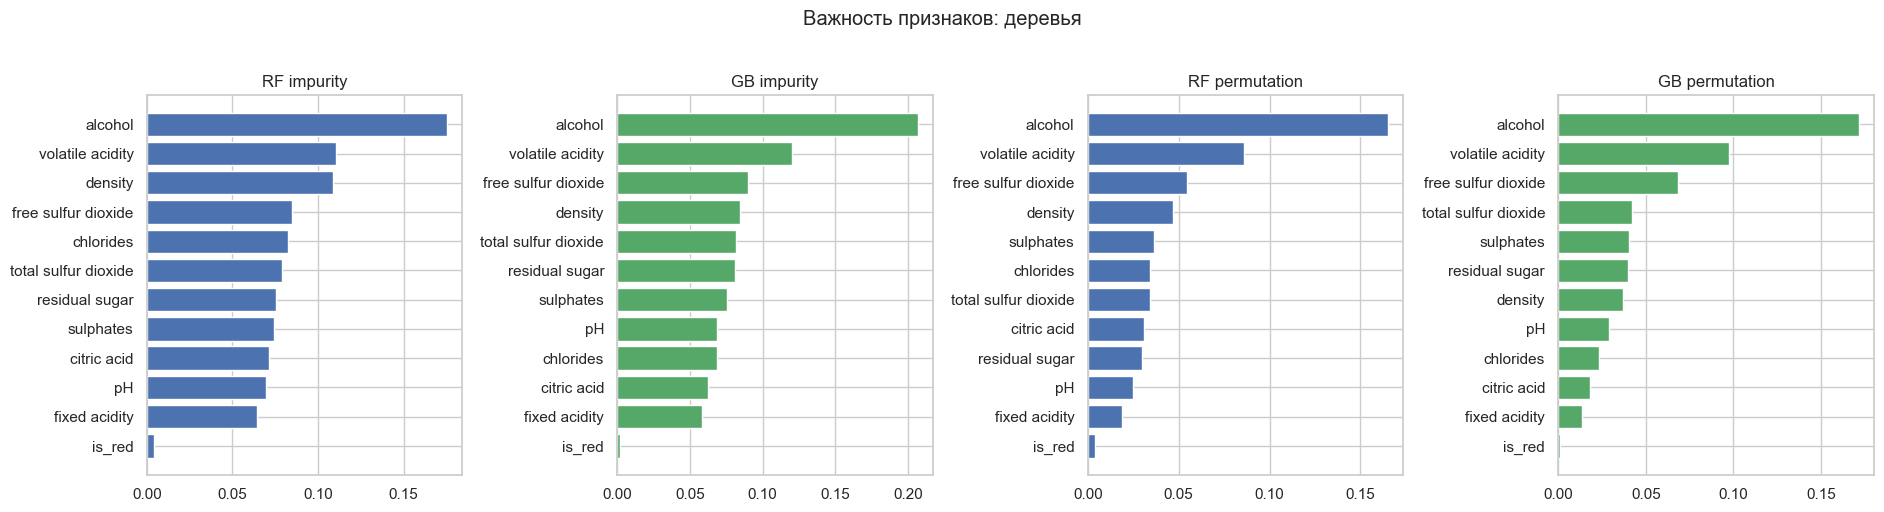

Спирмен между рейтингами:
                RF impurity  GB impurity  RF permutation  GB permutation  LR |std coef|  |corr| with quality
RF impurity            1.00         0.91            0.94            0.82           0.31                 0.55
GB impurity            0.91         1.00            0.88            0.95           0.39                 0.29
RF permutation         0.94         0.88            1.00            0.85           0.17                 0.46
GB permutation         0.82         0.95            0.85            1.00           0.26                 0.12


,RF impurity,GB impurity,RF permutation,GB permutation,LR |std coef|
1,alcohol,alcohol,alcohol,alcohol,density
2,volatile acidity,volatile acidity,volatile acidity,volatile acidity,residual sugar
3,density,free sulfur dioxide,free sulfur dioxide,free sulfur dioxide,alcohol
4,free sulfur dioxide,density,density,total sulfur dioxide,volatile acidity
5,chlorides,total sulfur dioxide,sulphates,sulphates,is_red


In [27]:
fig, axes = plt.subplots(1, 4, figsize=(19, 5), sharey=False)
for ax, col, color in zip(axes, ['RF impurity', 'GB impurity', 'RF permutation', 'GB permutation'],
                          ['#4C72B0', '#55A868', '#4C72B0', '#55A868']):
    s = imp[col].sort_values()
    ax.barh(s.index, s.values, color=color); ax.set_title(col)
plt.suptitle('Важность признаков: деревья', y=1.02); plt.tight_layout(); plt.show()

# согласованность рейтингов признаков (корреляция рангов Спирмена)
print('Спирмен между рейтингами:')
print(imp.corr(method='spearman').round(2).loc[['RF impurity', 'GB impurity', 'RF permutation', 'GB permutation'],
                                             ['RF impurity', 'GB impurity', 'RF permutation', 'GB permutation', 'LR |std coef|', '|corr| with quality']].to_string())
top5 = {c: list(imp[c].sort_values(ascending=False).index[:5]) for c in imp.columns[:5]}
pd.DataFrame(top5, index=[1, 2, 3, 4, 5])

### Выводы по feature importance

* **`alcohol` — №1** у обеих моделей по всем способам. Это совпадает с EDA (r ≈ 0.44).
* Дальше `volatile acidity`, `free sulfur dioxide`, `density`. `free sulfur dioxide` почти не коррелирует с quality линейно (≈ 0.06), но деревья его используют, значит, зависимость нелинейная.
* `chlorides` коррелирует (−0.20), а важность низкая: он дублирует другие признаки. `is_red` деревьям почти не нужен: тип вина «зашит» в другие признаки.
* Рейтинги леса и бустинга согласованы (корреляция Спирмена 0.82–0.95), с линейной моделью слабо (0.2–0.4). Большой коэффициент `residual sugar` у линейной модели — следствие дублирования признаков.

### Можно ли по важности утверждать, что признак *вызывает* изменение качества? **Нет.**

Важность показывает, что признак *помогает угадать* оценку, а не что он её причина. Признаки связаны между собой, есть скрытые факторы (зрелость винограда, сорт), оценка субъективна, а разные методы дают разные рейтинги. Для выводов о причинах нужен эксперимент с вмешательством.

### Итог раздела 9: важность признаков

Я посчитала важность встроенным способом и permutation importance на кросс-валидации: перемешиваю признак и смотрю, насколько вырастает ошибка. Главный признак — алкоголь, потом летучая кислотность, свободный диоксид серы и плотность. Это совпадает с EDA, но свободный диоксид серы линейно почти не коррелирует с качеством, а деревья его используют: значит, зависимость нелинейная. Важность не означает причинность: она показывает полезность для предсказания, а не что изменение признака меняет качество — есть скрытые факторы, например зрелость винограда.

## 10. Анализ ошибок лучшей модели

Лучшую модель выбираем **по CV RMSE на train** (не по тесту).

In [28]:
best_name = final.loc[['Linear Regression', 'Ridge + RBF', 'Random Forest', 'Gradient Boosting'], 'CV RMSE'].idxmin()
best_model = {'Linear Regression': lr, 'Ridge + RBF': rbf_ridge, 'Random Forest': rf, 'Gradient Boosting': gb}[best_name]
print(f'Лучшая модель по CV RMSE: {best_name}')
print(final.loc[['Random Forest', 'Gradient Boosting'], ['CV RMSE', 'CV std']].round(4))

pred = pd.Series(best_model.predict(X_test), index=X_test.index)
err = y_test - pred                       # положительная ошибка = модель занизила оценку
print(f'\nTest RMSE = {rmse(y_test, pred):.3f}, MAE = {mae(y_test, pred):.3f}, средняя ошибка (bias) = {err.mean():.3f}')

Лучшая модель по CV RMSE: Random Forest
                   CV RMSE  CV std
Random Forest       0.6125  0.0132
Gradient Boosting   0.6144  0.0107

Test RMSE = 0.593, MAE = 0.424, средняя ошибка (bias) = -0.039


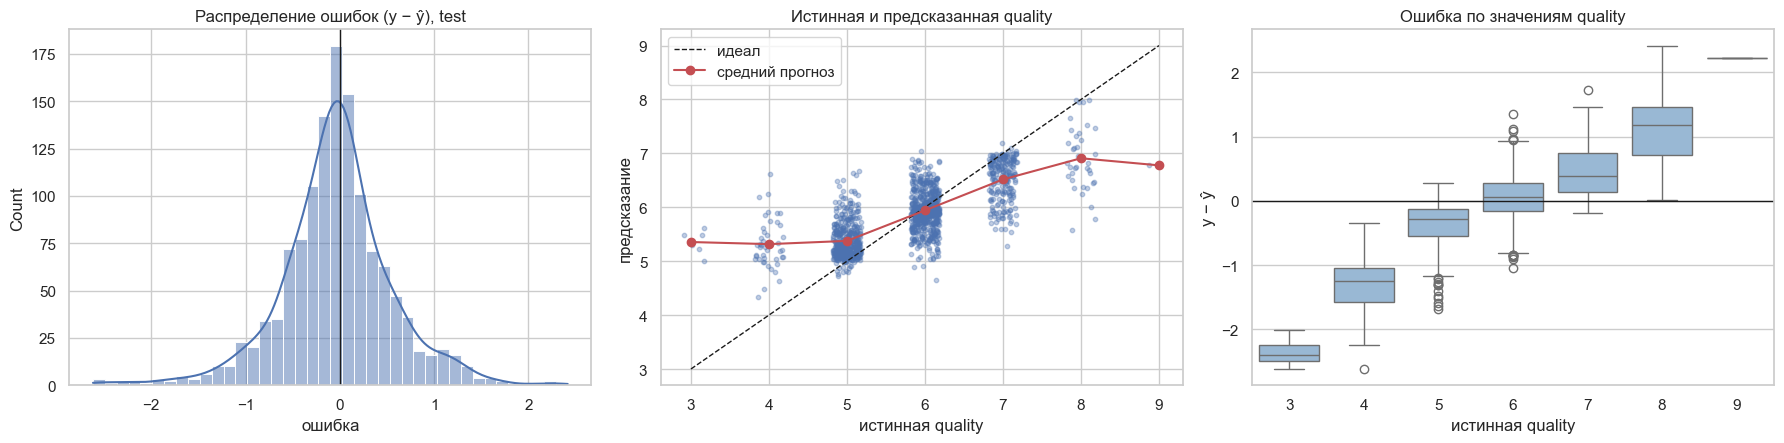

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))

sns.histplot(err, bins=40, kde=True, ax=axes[0], color='#4C72B0')
axes[0].axvline(0, color='k', lw=1)
axes[0].set(title='Распределение ошибок (y − ŷ), test', xlabel='ошибка')

jit = np.random.default_rng(SEED).uniform(-0.18, 0.18, len(y_test))
axes[1].scatter(y_test + jit, pred, s=10, alpha=.35)
axes[1].plot([3, 9], [3, 9], 'k--', lw=1, label='идеал')
axes[1].plot(sorted(y_test.unique()), pred.groupby(y_test).mean().sort_index(), 'r-o', label='средний прогноз')
axes[1].set(title='Истинная и предсказанная quality', xlabel='истинная quality', ylabel='предсказание'); axes[1].legend()

sns.boxplot(x=y_test.values, y=err.values, ax=axes[2], color='#8FB8DE')
axes[2].axhline(0, color='k', lw=1)
axes[2].set(title='Ошибка по значениям quality', xlabel='истинная quality', ylabel='y − ŷ')
plt.tight_layout(); plt.show()

In [30]:
by_q = pd.DataFrame({'y': y_test, 'pred': pred, 'err': err}).groupby('y').agg(
    n=('err', 'size'), mean_pred=('pred', 'mean'), bias=('err', 'mean'),
    MAE=('err', lambda e: e.abs().mean()), RMSE=('err', lambda e: np.sqrt((e ** 2).mean())))
by_q.round(3)

,n,mean_pred,bias,MAE,RMSE
y,,,,,
3,6,5.356,-2.356,2.356,2.364
4,43,5.317,-1.317,1.317,1.394
5,428,5.377,-0.377,0.386,0.505
6,567,5.942,0.058,0.291,0.378
7,216,6.517,0.483,0.487,0.628
8,39,6.910,1.090,1.090,1.233
9,1,6.778,2.222,2.222,2.222


In [31]:
within = lambda k: (err.abs() <= k).mean()
print(f'Доля объектов с |ошибкой| ≤ 0.5: {within(.5):.1%}, ≤ 1: {within(1):.1%}, > 1: {1 - within(1):.1%}')
print(f'Точное совпадение при округлении прогноза до целого: {(pred.round() == y_test).mean():.1%}')
print(f'Для сравнения, baseline (всегда 6): {(y_test == 6).mean():.1%}')

Доля объектов с |ошибкой| ≤ 0.5: 68.8%, ≤ 1: 90.2%, > 1: 9.8%
Точное совпадение при округлении прогноза до целого: 68.5%
Для сравнения, baseline (всегда 6): 43.6%


In [32]:
worst = X_test.assign(quality=y_test, pred=pred.round(2), error=err.round(2), abs_err=err.abs().round(2),
                      in_train=seen_in_train).sort_values('abs_err', ascending=False).head(10)
# z-оценка признака относительно train — чтобы увидеть, чем объект необычен
z = ((X_test.loc[worst.index] - X_train.mean()) / X_train.std())
worst['самый_необычный_признак'] = z.abs().idxmax(axis=1).values
worst['его_z'] = [round(z.loc[i, c], 1) for i, c in zip(worst.index, worst['самый_необычный_признак'])]
worst[['quality', 'pred', 'error', 'alcohol', 'volatile acidity', 'density', 'residual sugar', 'free sulfur dioxide',
       'is_red', 'самый_необычный_признак', 'его_z', 'in_train']]

,quality,pred,error,alcohol,volatile acidity,density,residual sugar,free sulfur dioxide,is_red,самый_необычный_признак,его_z,in_train
2339,3,5.62,-2.62,12.6,0.390,0.99150,4.60,5.0,0,alcohol,1.8,False
6107,4,6.61,-2.61,11.5,0.260,0.99020,2.60,75.0,0,free sulfur dioxide,2.5,False
1850,3,5.49,-2.49,9.8,0.260,0.99800,16.20,41.0,0,residual sugar,2.2,False
3287,3,5.49,-2.49,9.4,0.250,0.99490,1.55,118.5,0,free sulfur dioxide,5.0,False
3005,8,5.58,2.42,10.5,0.220,0.99440,6.80,12.0,0,pH,-1.3,False
1374,3,5.31,-2.31,9.8,0.815,0.99471,1.20,16.0,1,chlorides,6.1,False
5369,4,6.25,-2.25,12.0,0.270,0.99094,2.40,15.0,0,alcohol,1.3,False
1403,8,5.77,2.23,10.0,0.330,0.99600,1.70,3.0,1,sulphates,3.9,False
1469,3,5.22,-2.22,9.7,0.980,0.99705,2.10,20.0,1,volatile acidity,3.9,False
2426,9,6.78,2.22,12.5,0.240,0.99055,2.00,27.0,0,alcohol,1.7,False


### Выводы по анализу ошибок

* **Распределение ошибок** центрировано около нуля: у ≈ 69% вин ошибка не больше 0.5, у ≈ 90% не больше 1, у ≈ 10% больше балла. Эти редкие крупные промахи поднимают RMSE (0.59) выше MAE (0.42).
* **По значениям quality.** Лучше всего предсказываются частые оценки (6: RMSE ≈ 0.38; 5 и 7: 0.5–0.6), хуже редкие (3: ≈ 2.4; 4: ≈ 1.4; 8: ≈ 1.2). Прогнозы **тянутся к среднему**: оценку 3 модель в среднем предсказывает ≈ 5.4, оценку 8 — ≈ 6.9 («регрессия к среднему»). Девятка в тесте одна, выводов по ней нет.
* **Почему редкие значения хуже.** Мало примеров; при неуверенности безопаснее предсказать ближе к центру; в лист дерева с редким вином попадают и обычные; сама оценка субъективна.
* **Худшие объекты** (таблица выше) — все с редкими оценками, и ни одного из них нет среди копий train. Возможные причины: (1) «хорошая» химия, но оценка 3–4 (вероятно, шум в оценке дегустатора: объекты 2339, 5369, 6107); (2) «обычная» химия, но оценка 8–9 (3005, 1403, 2426); (3) выбросы по признакам (1374, 3287, 1469), таких вин в train единицы.
* **Вывод.** Модель надёжна для типичных вин, но не находит «выдающиеся» или «бракованные».

### Итог раздела 10: ошибки и дубликаты

Ошибка до 0.5 балла у 69% объектов. Модель хуже на редких оценках и тянет их к среднему: оценку 3 в среднем предсказывает около 5.4. Причины: мало примеров, субъективность дегустаторов, квадратичная ошибка поощряет осторожные прогнозы. Ещё в данных 18% дубликатов, поэтому на «новых» винах без копий в train RMSE около 0.68–0.69, но порог 0.70 всё равно выполняется.

## 11. Итоги

### Проверка требований ТЗ

| Требование | Где выполнено |
|---|---|
| Первичный анализ данных с содержательными выводами | раздел 2 |
| Разбиение, `random_state`, обоснование размера и способа, проблемы многократной оценки на тесте | раздел 1 |
| Baseline-константа, обоснование выбора константы, результат в таблице | раздел 4, 8 |
| RMSE и MAE у каждой модели, ответы на вопросы про метрики | разделы 3, 8 |
| Линейная регрессия, коэффициенты, масштабирование; улучшение Ridge + RBF (RMSE < 0.70) | раздел 5, 5.1 |
| Random Forest + feature importance | разделы 6, 9 |
| Gradient Boosting + feature importance | разделы 7, 9 |
| Честное сравнение на одних данных, итоговая таблица, какие модели лучше baseline | раздел 8 |
| Визуализация и сравнение важности признаков, сопоставление с EDA, вопрос про причинность | раздел 9 |
| Анализ ошибок лучшей модели | раздел 10 |
| Нет утечек: тест используется только для финальной оценки, преобразования внутри `Pipeline`, выбор по CV | разделы 1, 3 |

In [33]:
best_test_rmse = final.loc[best_name, 'Test RMSE']
print(f'Лучшая модель (по CV): {best_name}')
print(f'RMSE на тесте = {best_test_rmse:.3f}  (порог 0.70, baseline = {final.loc["Baseline", "Test RMSE"]:.3f})')
print(f'RMSE на "новых" объектах теста = {final.loc[best_name, "New RMSE"]:.3f}')
assert best_test_rmse < 0.70, 'порог качества не достигнут'
main_table

Лучшая модель (по CV): Random Forest
RMSE на тесте = 0.593  (порог 0.70, baseline = 0.874)
RMSE на "новых" объектах теста = 0.683


,RMSE,MAE
Модель,,
Baseline,0.874,0.686
Linear Regression,0.728,0.568
Ridge + RBF,0.669,0.519
Random Forest,0.593,0.424
Gradient Boosting,0.588,0.391


### Главные выводы

1. **Порог RMSE < 0.70 достигнут:** лес и бустинг ≈ 0.59, Ridge + RBF ≈ 0.67; обычная линейная регрессия (0.73) нет. Baseline 0.87.
2. Результат стабилен при смене разбиения и остаётся ниже 0.70 на «новых» винах (≈ 0.68–0.69), но там запас небольшой.
3. Ключевые признаки: **алкоголь**, затем `volatile acidity`, `free sulfur dioxide`, `density`. Это ассоциации, а не причины.
4. Лучше всего предсказываются типичные вина, редкие оценки «тянутся» к среднему.
5. Ограничения: субъективная оценка, 18% дубликатов, мало редких классов.